# 🧠 ¿Qué es una Red Neuronal?
Antes de ver cómo aprende Word2Vec, imagínate una red neuronal como una **máquina ajustable de tomar decisiones**.

Piensa en cómo decides si vas o no a un asado el fin de semana:
*   **Entradas:** ¿Hace lindo día? ¿Van tus amigos? ¿Tenés que trabajar el lunes?
*   **Pesos (Importancia):** Si te molesta mucho trabajar con sueño, el peso de "trabajar el lunes" va a ser muy negativo y tendrá más importancia en tu decisión.
*   **El Ajuste:** Al principio, la máquina toma decisiones al azar y se equivoca. Cada vez que comete un error, ajusta ligeramente sus perillas (pesos) para que la próxima vez su predicción sea más acertada. ¡Eso es el aprendizaje automático!

## 🗺️ ¿Qué es un Word Embedding? (Vectores de palabras)

Las computadoras no entienden el significado de las palabras de forma nativa. Para ellas, "perro" y "gato" son solo cadenas de texto sin ninguna relación.

Un **Word Embedding** es simplemente darle a cada palabra una **dirección en un mapa multidimensional** (un vector de números).
*   Si dos palabras tienen significados o usos similares, la máquina las ubicará muy cerca en este mapa geométrico.
*   Si no tienen ninguna relación, la máquina las pondrá en esquinas opuestas o totalmente alejadas.

### Intuición Geométrica del Coseno: ¿Por qué medimos ángulos y no distancias?

En espacios de alta dimensión, la distancia geométrica común (medir en línea recta con una regla) nos engaña. Si un documento habla de caballos en 5 páginas y otro habla de caballos en 100 páginas, la regla dirá que están "lejos" solo porque uno tiene muchos más números que el otro.

Para solucionarlo, usamos la **Similitud de Coseno**, que ignora el largo de las flechas (vectores) y mide únicamente el **ángulo $	heta$ (tita)** entre ellos:

$$\cos(\theta) = \frac{\mathbf{u} \cdot \mathbf{v}}{\|\mathbf{u}\| \|\mathbf{v}\|}$$

**¿Cómo leer esta fórmula de forma sencilla?**
*   **El numerador ($\mathbf{u} \cdot \mathbf{v}$):** Es el *producto punto*. Multiplica coordenada por coordenada. Si las coordenadas coinciden en signos (ambas positivas o ambas negativas en una dimensión), este valor sube. Es como un detector de coincidencias.
*   **El denominador ($\|\mathbf{u}\| \|\mathbf{v}\|$):** Representa el tamaño o largo de cada vector. Al dividir por el tamaño, "neutralizamos" el efecto de que una palabra sea muy larga o muy frecuente. Así, solo nos importa la **dirección**.

*   **Ángulo de 0° ($\cos = 1$):** Las palabras apuntan exactamente en la misma dirección (ej. *cantar* y *cantando*).
*   **Ángulo de 90° ($\cos = 0$):** Son perpendiculares, lo que significa que no tienen ninguna relación semántica (ej. *cantar* y *facón*).
*   **Ángulo de 180° ($\cos = -1$):** Apuntan en direcciones opuestas.

# Word2Vec: El Juego de Adivinar el Contexto

Como bien decía el lingüista J.R. Firth: *"Conocerás una palabra por las compañeras que tiene"*.

Word2Vec aprende a ubicar las palabras en el mapa mediante un juego de auto-supervisión: intentar predecir el contexto que rodea a una palabra central.

```
                   ventana c=2
          ◄─────────────────────────►
  ... pongo   a  [cantar]  al  compás ...
               contexto  target
```

### La Fórmula del Objetivo General (Skip-gram)

Queremos que nuestro modelo maximice la probabilidad de adivinar correctamente el contexto de todas las palabras del libro. Matemáticamente se expresa así:

$${L} = \frac{1}{T} \sum_{t=1}^{T} \sum_{\substack{j=-c \\ j \neq 0}}^{c} \log P(w_{t+j} \mid w_t)$$

**Explicación:**
*   $\sum_{t=1}^{T}$ significa que vamos a recorrer todo el texto, palabra por palabra ($T$ es el total de palabras).
*   $\sum_{j=-c}^{c}$ mira dentro de una pequeña ventana (de tamaño $c$) a la izquierda y derecha de la palabra actual.
*   $\log P(w_{t+j} \mid w_t)$ calcula la probabilidad (en escala logarítmica para que sea más fácil sumar que multiplicar) de encontrar la palabra de contexto $w_{t+j}$ dada la palabra central $w_t$.

Para calcular esa probabilidad de transición individual $P(w_O \mid w_I)$, se usa la clásica función **Softmax**:

$$P(w_O \mid w_I) = \frac{\exp(\mathbf{v}_{w_O}^{\prime \top} \mathbf{v}_{w_I})}{\sum_{w=1}^{|V|} \exp(\mathbf{v}_{w}^{\prime \top} \mathbf{v}_{w_I})}$$

*   **El numerador (arriba):** Evalúa la afinidad actual entre la palabra central (vector $\mathbf{v}$) y la palabra de contexto real (vector $\mathbf{v}^\prime$).
*   **El denominador (abajo):** Suma esa misma afinidad para **absolutamente todas** las palabras del vocabulario ($|V|$). Esto sirve para normalizar la probabilidad y que el resultado final sea un porcentaje de 0% a 100%.

### El Atajo Inteligente: Muestreo Negativo (Negative Sampling)

Calcular el denominador de la fórmula anterior es extremadamente lento porque requiere sumar sobre miles de palabras en cada paso. Para evitarlo, Word2Vec usa una fórmula simplificada basada en imanes (atracción y repulsión):

$${L}_{NS} = \log \sigma(\mathbf{v}_{w_O}^{\prime \top} \mathbf{v}_{w_I}) + \sum_{i=1}^{k} \mathbb{E}_{w_i \sim P_n(w)} \left[ \log \sigma(-\mathbf{v}_{w_i}^{\prime \top} \mathbf{v}_{w_I})\right]$$

**Explicación de la matemática de imanes:**
*   **Parte izquierda $\log \sigma(\mathbf{v}_{w_O}^{\prime \top} \mathbf{v}_{w_I})$ (Atracción):** Toma la palabra central y su contexto real. $\sigma$ es la función sigmoide que convierte el score en una probabilidad. Queremos maximizar esto para **atraer** y juntar ambas palabras en el mapa semántico.
*   **Parte derecha $\sum_{i=1}^{k} [\dots]$ (Repulsión):** Tomamos un puñado de $k$ palabras totalmente al azar (muestras negativas $w_i$) que no tienen relación. El signo negativo dentro de la fórmula hace que el modelo intente minimizar su similitud, funcionando como una fuerza que **repele** y aleja estas palabras de la palabra central en nuestro mapa.

## 🪄 Álgebra de Palabras: Operaciones mágicas con vectores

Una de las propiedades más sorprendentes que surge de este entrenamiento es que podemos hacer matemática con los conceptos:

$$\text{Rey} - \text{Hombre} + \text{Mujer} = \text{Reina}$$

¿Por qué pasa esto? Porque durante el juego de atracción y repulsión, la máquina descubre de manera autónoma que la diferencia de dirección entre "Hombre" y "Mujer" representa el concepto de **género**, y puede aplicar esa misma diferencia geométrica a cualquier otro par de conceptos.

### Ejemplo práctico con el Martín Fierro

Tomemos la línea: **"aquí me pongo a cantar"**

1.  **Palabra central:** `pongo`
2.  **Contexto real (Atracción):** `aquí`, `me`, `a`, `cantar` (Se les asigna etiqueta 1 para juntarlos).
3.  **Contexto falso (Repulsión):** `vaca`, `tren`, `indio` (Se eligen al azar del diccionario y se les asigna etiqueta 0 para separarlos en el mapa).

¡Eso es todo! Repitiendo este simple juego de imanes miles de veces a lo largo de todo el poema, el mapa semántico se organiza solo de forma perfecta.

```
🗺️ MAPA SEMÁNTICO EN ENTRENAMIENTO:

         [ me ]  ◄── (Atracción) ──►  [ pongo ]  ── (Repulsión) ──►  [ vaca ]
   (Aparecen juntos en la estrofa)                            (Palabra al azar)
```

In [ ]:
!pip install gensim==4.4.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 66.6 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import warnings
import torch
import torch.nn as nn
import torch.nn.functional as F
import random
import requests
import unicodedata
import logging
import time

from gensim.models import Word2Vec
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from collections import defaultdict, Counter
from scipy.stats import gaussian_kde
from typing import Iterable, Callable, Any
from pydantic import BaseModel, PositiveInt

In [ ]:
class Corpus():
  def __init__(self, documents):
    self.raw_documents = documents

  def get_raw_documents(self):
    return self.raw_documents

  def sample(self, lenght=3):
    for i in range(min(lenght, len(self.raw_documents))):
      print(f'\n ==== Document {i+1} ==== \n\n{self.raw_documents[i][:250]}')

In [ ]:
class DocumentsCleaner():

    @staticmethod
    def _transform(
        documents: Iterable[str],
        function: Callable[[str], str],
        *,
        discard_empty: bool = False
    ) -> list[str]:
        """Aplica una transformación y devuelve una nueva lista."""
        result = [function(document) for document in documents]
        return [doc for doc in result if doc] if discard_empty else result

    def delete_init_final_chars(self, documents):
        """Elimina espacios al inicio y al final y descarta documentos vacíos."""
        return self._transform(
            documents, str.strip, discard_empty=True
        )

    def to_lower_case(self, documents):
        """Convierte los documentos a minúsculas."""
        return self._transform(documents, str.lower)

    def delete_accents(self, documents):
        """Elimina los diacríticos de los documentos."""
        def remove_accents(document):
            return ''.join(
                char
                for char in unicodedata.normalize('NFD', document)
                if unicodedata.category(char) != 'Mn'
            )

        return self._transform(documents, remove_accents)

    def conserve_letters_numbers_spaces_and_signs(self, documents):
        """Conserva los caracteres permitidos."""
        pattern = re.compile(r'[^a-zñ0-9\s.,;:¿?¡!"“”\'()\-—…]')

        return self._transform(
            documents,
            lambda document: pattern.sub('', document)
        )

    def normalize_multiple_spaces(self, documents):
        """Reduce los espacios consecutivos a uno solo."""
        return self._transform(
            documents,
            lambda document: re.sub(r'\s+', ' ', document).strip()
        )

    def conserve_documents_with_than_words(self, documents, n=5):
        """Conserva documentos con más de n palabras."""
        return [
            document
            for document in documents
            if document and len(document.split()) > n
        ]

    def apply_rgx(self, documents, rgx):
        """Descarta documentos que coinciden con el patrón
        o que tienen menos de dos líneas.
        """
        pattern = re.compile(rgx)

        return [
            document
            for document in documents
            if not pattern.match(document)
            and len(document.split('\n')) >= 2
        ]

In [ ]:
class Tokenizer():

  def tokenize(self, documents):
    """
    Separa palabras, números y signos de puntuación
    """
    tokenized_documents = []

    for i, doc in enumerate(documents):
        tokens = re.findall(r'\w+|[^\w\s]', doc, flags=re.UNICODE)
        tokenized_documents.append(tokens)

    self.tokens = tokenized_documents

  def get_tokens(self):
    return self.tokens

  def sample(self, lenght=3):
    for i in range(min(lenght, len(self.tokens))):
      print(f'\n ==== Document {i+1} ==== \n\n{self.tokens[i][:250]}')

In [ ]:
class Word2VecParams(BaseModel):
  vector_size: PositiveInt = 50
  window: PositiveInt = 4
  min_count: PositiveInt = 2
  negative: PositiveInt = 10
  epochs: PositiveInt = 100
  workers: PositiveInt = 4
  seed: int = 42


In [ ]:
class Word2Vector():
    """Entrena y consulta un modelo Word2Vec."""

    def __init__(
        self,
        documents,
        hiper_params: Word2VecParams,
        verbose: bool = False
    ):

        self.documents = tuple(tuple(doc) for doc in documents)
        self._logger = logging.getLogger(__name__)

        if verbose:
            print("=" * 60)
            print("ENTRENANDO MODELO WORD2VEC")
            print(
                f"Dimensión={hiper_params.vector_size} | Ventana={hiper_params.window} "
                f"| Épocas={hiper_params.epochs}"
            )
            print("=" * 60)

        start_time = time.perf_counter()

        self.model = Word2Vec(
            sentences=self.documents,
            vector_size=hiper_params.vector_size,
            window=hiper_params.window,
            min_count=hiper_params.min_count,
            negative=hiper_params.negative,
            epochs=hiper_params.epochs,
            workers=hiper_params.workers,
            seed=hiper_params.seed,
        )

        self.words = tuple(self.model.wv.index_to_key)
        self.vocab_to_index = {
            word: i for i, word in enumerate(self.words)
        }

        if verbose:
            elapsed = time.perf_counter() - start_time
            print(f"Entrenamiento completado en {elapsed:.2f} s")
            print(f"Vocabulario: {len(self.words):,} palabras")
            print("=" * 60)

    @property
    def vectors(self):
        """Devuelve una copia de la matriz de embeddings."""
        return self.model.wv.vectors.copy()

    def get_embeddings_data(self):
        """Devuelve el vocabulario y una copia de sus embeddings."""
        return self.words, self.vectors

    def get_word_vector(self, word):
        """Obtiene el embedding de una palabra."""
        if word not in self.model.wv:
            raise ValueError(
                f"La palabra {word!r} no está en el vocabulario Word2Vec."
            )

        return self.model.wv[word].copy()

    def map_vocab_to_index(self):
        """Devuelve el índice de cada palabra del vocabulario."""
        return self.vocab_to_index.copy()

    def print_summary(self, sample_size=20):
        """Muestra las dimensiones y una muestra del vocabulario."""
        if sample_size < 0:
            raise ValueError("sample_size no puede ser negativo.")

        vocab_size = len(self.words)
        vector_size = self.model.wv.vector_size

        print("=" * 60)
        print("RESUMEN DEL MODELO WORD2VEC")
        print("=" * 60)
        print(f"Vocabulario: {vocab_size:,} palabras")
        print(f"Dimensión: {vector_size}D")
        print(f"Matriz: ({vocab_size}, {vector_size})")
        print("-" * 60)
        print(f"Primeras {min(sample_size, vocab_size)} palabras:")

        for i, word in enumerate(self.words[:sample_size], start=1):
            print(f"{i:>4}. {word}")

        print("=" * 60)

    def compute_vector_analogy(
        self, positive, negative=(), top_n=10, prints=True
    ):
        """Calcula analogías vectoriales y devuelve resultados y ausentes."""
        if top_n < 1:
            raise ValueError("top_n debe ser mayor que cero.")

        positive = tuple(positive)
        negative = tuple(negative)
        required_words = positive + negative

        missing_words = list(dict.fromkeys(
            word for word in required_words
            if word not in self.model.wv
        ))

        if missing_words:
            return None, missing_words

        if not positive:
            raise ValueError("Se necesita al menos una palabra positiva.")

        results = self.model.wv.most_similar(
            positive=list(positive),
            negative=list(negative),
            topn=top_n,
        )

        if prints:
            self._print_analogy_results(
                positive, negative, results
            )

        return results, []

    def gen_text(
        self,
        seed,
        length=15,
        temperature=0.7,
        top_k=8,
        random_seed=42,
    ):
        """Genera una secuencia explorando vecinos semánticos."""
        if length < 1:
            raise ValueError("length debe ser mayor que cero.")
        if temperature <= 0:
            raise ValueError("temperature debe ser mayor que cero.")
        if top_k < 1:
            raise ValueError("top_k debe ser mayor que cero.")

        current_word = seed.strip().lower()

        if current_word not in self.model.wv:
            raise ValueError(
                f"La palabra {seed!r} no está en el vocabulario Word2Vec."
            )

        rng = np.random.default_rng(random_seed)
        result = [current_word]

        for _ in range(length - 1):
            neighbors = self.model.wv.most_similar(
                current_word,
                topn=min(top_k, len(self.words) - 1),
            )

            if not neighbors:
                break

            candidates, similarities = zip(*neighbors)
            probabilities = self._softmax(
                similarities, temperature
            )

            current_word = rng.choice(
                candidates, p=probabilities
            )
            result.append(current_word)

        return " ".join(result)

    def to_pandas_df(self):
        """Devuelve los embeddings en un DataFrame."""
        return pd.DataFrame(
            self.vectors,
            index=self.words,
            columns=[
                f"Dim_{i + 1}"
                for i in range(self.model.wv.vector_size)
            ],
        )

    @staticmethod
    def _softmax(values, temperature=1.0):
        """Calcula softmax con temperatura y estabilidad numérica."""
        if temperature <= 0:
            raise ValueError("temperature debe ser mayor que cero.")

        logits = np.asarray(values, dtype=float) / temperature
        logits -= logits.max()
        exp_logits = np.exp(logits)

        return exp_logits / exp_logits.sum()

    @staticmethod
    def _print_analogy_results(positive, negative, results):
        equation = " + ".join(map(repr, positive))

        if negative:
            equation += " - " + " - ".join(map(repr, negative))

        print("=" * 60)
        print("ANALOGÍA VECTORIAL")
        print(equation)
        print("-" * 60)

        for word, similarity in results:
            bar = "█" * int(max(0, similarity) * 10)
            print(f"{word:<22} {similarity:>8.4f}  {bar}")

        print("=" * 60)

In [ ]:
# Paso 1 - Cargar, generar u obtener nuestro corpus (El universo de Documentos), como estamos trabajando con solo el Martin Fierro, nuestro corpus será cada una de las estrofas,
# que vamos a llamar documentos.

# URL del archivo JSON con las estrofas
url_json = 'https://raw.githubusercontent.com/Lautauro/fierrodiario/refs/heads/pages/json/estrofas.json'

print(f"Cargando datos desde {url_json}...")
response = requests.get(url_json)
response.raise_for_gradual_behavior = True # Asegura que la descarga sea correcta
data_json = response.json()


# Vamos a extraer los textos de las estrofas
raw_stanzas = []
if isinstance(data_json, dict) and 'estrofas' in data_json:
    # Si es un diccionario con la key 'estrofas'
    raw_stanzas = [item.get('texto', '') if isinstance(item, dict) else str(item) for item in data_json['estrofas']]
elif isinstance(data_json, list):
    # Si es una lista directamente
    raw_stanzas = [item.get('texto', '') if isinstance(item, dict) else str(item) for item in data_json]

corpus = Corpus(raw_stanzas)

corpus.sample(lenght=5)

Cargando datos desde https://raw.githubusercontent.com/Lautauro/fierrodiario/refs/heads/pages/json/estrofas.json...

 ==== Document 1 ==== 

Aquí me pongo á cantar
Al compás de la vigüela,
Que el hombre que lo desvela
Una pena estraordinaria,
Como la ave solitaria
Con el cantar se consuela.

 ==== Document 2 ==== 

Pido á los Santos del Cielo
Que ayuden mi pensamiento,
Les pido en este momento
Que voy á cantar mi historia
Me refresquen la memoria
Y aclaren mi entendimiento.

 ==== Document 3 ==== 

Vengan Santos milagrosos,
Vengan todos en mi ayuda,
Que la lengua se me añuda
Y se me turba la vista;
Pido á mi Dios que me asista
En una ocasión tan ruda.

 ==== Document 4 ==== 

Yo he visto muchos cantores,
Con famas bien otenidas,
Y que despues de adquiridas
No las quieren sustentar:
Parece que sin largar
Se cansaron en partidas.

 ==== Document 5 ==== 

Mas ande otro criollo pasa
Martin Fierro ha de pasar,
Nada lo hace recular
Ni las fantasmas lo espantan;
Y dende que todos cantan
Yo ta

In [ ]:
# Paso 2 - Limpieza de nuestro corpus

raw_documents = corpus.get_raw_documents()

cleaner = DocumentsCleaner()

cleaned_documents = cleaner.delete_init_final_chars(raw_documents)
cleaned_documents = cleaner.to_lower_case(cleaned_documents)
cleaned_documents = cleaner.delete_accents(cleaned_documents)
cleaned_documents = cleaner.normalize_multiple_spaces(cleaned_documents)

total_documents = len(cleaned_documents)

print(f'Total de documentos limpiados: {total_documents}')
print("Documentos únicos:", len(set(cleaned_documents)))
print('\nEjemplos:')
for i in range(min(3, total_documents)):
    print(f'\nDocumento {i+1}: {cleaned_documents[i][:250]}')

Total de documentos limpiados: 398
Documentos únicos: 398

Ejemplos:

Documento 1: aqui me pongo a cantar al compas de la viguela, que el hombre que lo desvela una pena estraordinaria, como la ave solitaria con el cantar se consuela.

Documento 2: pido a los santos del cielo que ayuden mi pensamiento, les pido en este momento que voy a cantar mi historia me refresquen la memoria y aclaren mi entendimiento.

Documento 3: vengan santos milagrosos, vengan todos en mi ayuda, que la lengua se me anuda y se me turba la vista; pido a mi dios que me asista en una ocasion tan ruda.


In [ ]:
# Paso 3 - Tokenizar ej. aqui me pongo a cantar -> ['aqui', 'me', 'pongo', 'a', 'cantar']

tokenizer = Tokenizer()

tokenizer.tokenize(cleaned_documents)

tokenizer.sample(lenght=5)

tokenized_documents = tokenizer.get_tokens()

# Podemos notar, que en nuestros ejemplos hay tokens que se repiten, por ej la coma ','.
# ¿Por qué no conviene eliminar los duplicados ahora?
# Si conviertes cada documento en un set, perderás información importante:
#  Frecuencia: no sabrás cuántas veces aparece una palabra.
#  Orden: no podrás reconstruir los versos ni estudiar secuencias de palabras.
#  Contexto: dificultarás el entrenamiento de modelos de lenguaje, como los modelos de n-gramas.


 ==== Document 1 ==== 

['aqui', 'me', 'pongo', 'a', 'cantar', 'al', 'compas', 'de', 'la', 'viguela', ',', 'que', 'el', 'hombre', 'que', 'lo', 'desvela', 'una', 'pena', 'estraordinaria', ',', 'como', 'la', 'ave', 'solitaria', 'con', 'el', 'cantar', 'se', 'consuela', '.']

 ==== Document 2 ==== 

['pido', 'a', 'los', 'santos', 'del', 'cielo', 'que', 'ayuden', 'mi', 'pensamiento', ',', 'les', 'pido', 'en', 'este', 'momento', 'que', 'voy', 'a', 'cantar', 'mi', 'historia', 'me', 'refresquen', 'la', 'memoria', 'y', 'aclaren', 'mi', 'entendimiento', '.']

 ==== Document 3 ==== 

['vengan', 'santos', 'milagrosos', ',', 'vengan', 'todos', 'en', 'mi', 'ayuda', ',', 'que', 'la', 'lengua', 'se', 'me', 'anuda', 'y', 'se', 'me', 'turba', 'la', 'vista', ';', 'pido', 'a', 'mi', 'dios', 'que', 'me', 'asista', 'en', 'una', 'ocasion', 'tan', 'ruda', '.']

 ==== Document 4 ==== 

['yo', 'he', 'visto', 'muchos', 'cantores', ',', 'con', 'famas', 'bien', 'otenidas', ',', 'y', 'que', 'despues', 'de', 'adqui

In [ ]:
# 1. Entrenar el modelo
w2v_params = Word2VecParams(
    vector_size=50,
    window=4,
    min_count=2,
    negative=10,
    epochs=150,
    workers=4,
    seed=42
)

w2v = Word2Vector(
    documents=tokenized_documents,
    hiper_params=w2v_params,
    verbose=True
)

# 2. Extraer datos
words, vecs = w2v.get_embeddings_data()

ENTRENANDO MODELO WORD2VEC
Dimensión=50 | Ventana=4 | Épocas=150
Entrenamiento completado en 3.75 s
Vocabulario: 1,000 palabras


In [ ]:
# 3. Mostrar resumen visual del entrenamiento
w2v.print_summary(sample_size=20)

RESUMEN DEL MODELO WORD2VEC
Vocabulario: 1,000 palabras
Dimensión: 50D
Matriz: (1000, 50)
------------------------------------------------------------
Primeras 20 palabras:
   1. ,
   2. .
   3. que
   4. y
   5. el
   6. la
   7. de
   8. —
   9. a
  10. en
  11. me
  12. no
  13. un
  14. se
  15. los
  16. lo
  17. al
  18. «
  19. las
  20. con


In [ ]:
# Crear el DataFrame de Pandas a nivel de palabras
df_w2v_words = w2v.to_pandas_df()

# Mostrar una parte de esta matriz (primeras 5 palabras y primeras 8 dimensiones)
print("=== VISTA PARCIAL DE LA MATRIZ DE EMBEDDINGS DE PALABRAS ===")
display(df_w2v_words.iloc[:5, :8])

=== VISTA PARCIAL DE LA MATRIZ DE EMBEDDINGS DE PALABRAS ===


,Dim_1,Dim_2,Dim_3,Dim_4,Dim_5,Dim_6,Dim_7,Dim_8
",",0.117845,0.436087,-0.093092,-0.354816,-0.266061,1.165374,-0.736653,0.263819
.,0.313571,0.119956,-0.276501,-1.604113,-0.234111,-1.055881,0.848461,-0.418536
que,0.755806,-1.697548,0.145118,-0.186925,-0.185643,1.236546,0.659603,0.536865
y,0.600700,-0.312081,1.017698,-0.876054,-0.198165,0.765746,-0.610816,-0.064111
el,0.847155,0.814141,-0.185677,1.052909,-0.028634,-0.280153,1.458350,1.003310


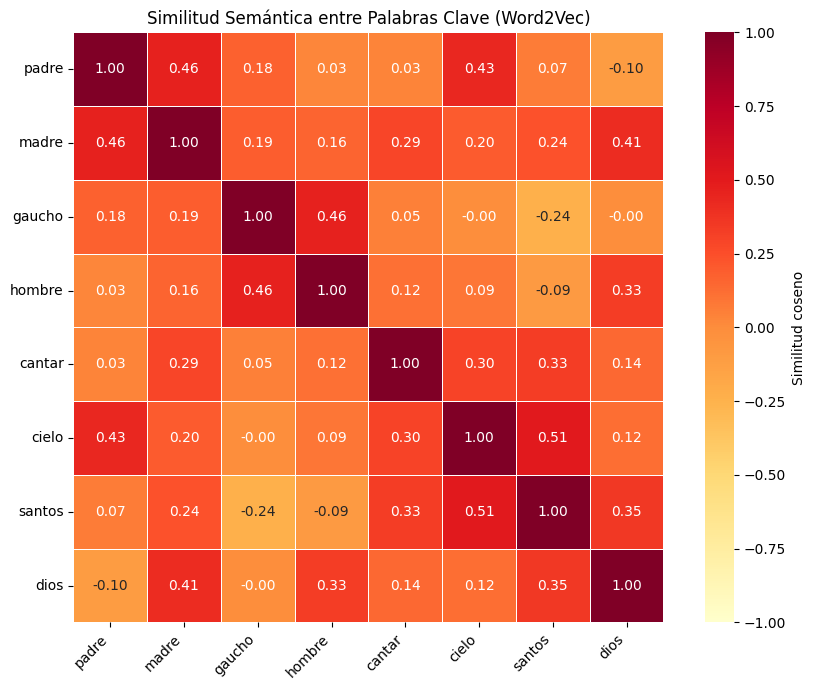

In [ ]:
# Seleccionar un grupo de palabras clave para analizar sus similitudes
palabras_analisis = [
    'padre', 'madre', 'gaucho', 'hombre',
    'cantar', 'cielo', 'santos', 'dios'
]

# Filtrar únicamente las que existan en el vocabulario
palabras_validas = [p for p in palabras_analisis if p in df_w2v_words.index]

# Obtener sus vectores desde el DataFrame
vectores_analisis = [w2v.get_word_vector(word=w_target) for w_target in palabras_validas]

# Calcular similitud coseno entre las palabras seleccionadas
matriz_similitud_palabras = cosine_similarity(vectores_analisis)

# Crear un DataFrame para facilitar la visualización de la similitud
df_similitud_palabras = pd.DataFrame(
    matriz_similitud_palabras,
    index=palabras_validas,
    columns=palabras_validas
)

# Graficar el mapa de calor de similitudes semánticas entre palabras usando un cmap cálido (YlOrRd)
plt.figure(figsize=(9, 7))
sns.heatmap(
    df_similitud_palabras,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={'label': 'Similitud coseno'}
)

plt.title('Similitud Semántica entre Palabras Clave (Word2Vec)')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
positivas = ['madre', 'gaucho']
negativas = ['padre']

# 1. Calcular analogía
resultados, faltantes = w2v.compute_vector_analogy(
    positive=positivas,
    negative=negativas,
    top_n=10
)

ANALOGÍA VECTORIAL
'madre' + 'gaucho' - 'padre'
------------------------------------------------------------
vas                      0.6541  ██████
cuidao                   0.6012  ██████
gueno                    0.5545  █████
polecia                  0.5529  █████
conteste                 0.5228  █████
toro                     0.5142  █████
sera                     0.4790  ████
quien                    0.4603  ████
puse                     0.4600  ████
has                      0.4585  ████


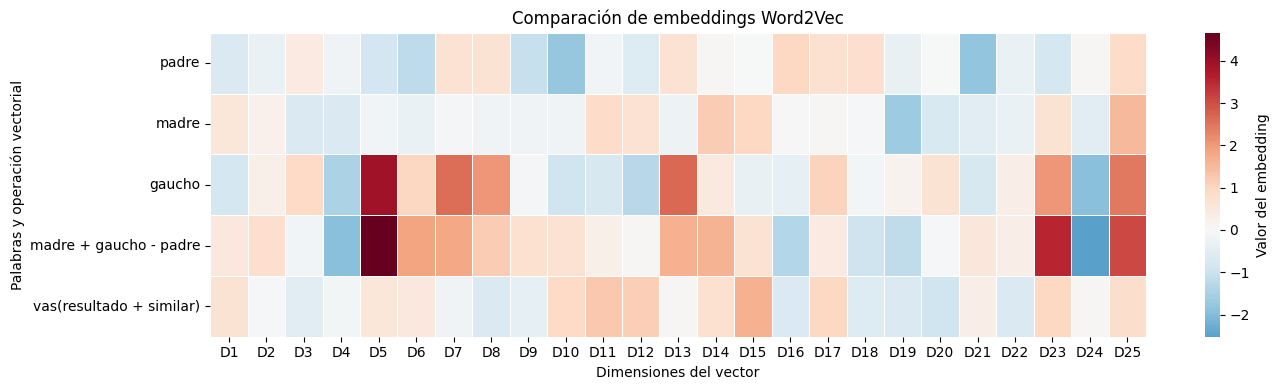

In [ ]:
v_padre = w2v.get_word_vector('padre')
v_madre = w2v.get_word_vector('madre')
v_gaucho = w2v.get_word_vector('gaucho')
v_operation = v_madre + v_gaucho - v_padre
v_result_most_similar = w2v.get_word_vector(resultados[0][0])

vectores = np.vstack([
    v_padre,
    v_madre,
    v_gaucho,
    v_operation,
    v_result_most_similar
])

nombres = ['padre', 'madre', 'gaucho', 'madre + gaucho - padre', f"{resultados[0][0]}(resultado + similar)" ]

# Mostrar las primeras 25 dimensiones para facilitar la lectura
n_dimensiones = min(25, vectores.shape[1])

df_vectores = pd.DataFrame(
    vectores[:, :n_dimensiones],
    index=nombres,
    columns=[f'D{i+1}' for i in range(n_dimensiones)]
)

# 4. Graficar el mapa de calor
plt.figure(figsize=(14, 4))

sns.heatmap(
    df_vectores,
    cmap='RdBu_r',
    center=0,
    annot=False,
    linewidths=0.4,
    cbar_kws={'label': 'Valor del embedding'}
)

plt.title('Comparación de embeddings Word2Vec')
plt.xlabel('Dimensiones del vector')
plt.ylabel('Palabras y operación vectorial')
plt.tight_layout()
plt.show()

#### La matemática en N dimensiones:
Aunque los vectores viven en $\mathbb{R}^{N}$, **dos vectores cualesquiera siempre definen un plano bidimensional** que pasa por el origen. El ángulo $\theta$ entre ellos en ese plano es invariante y se calcula exactamente como:

$$\cos(\theta) = \frac{\mathbf{u} \cdot \mathbf{v}}{\|\mathbf{u}\| \|\mathbf{v}\|} \implies \theta = \arccos\left(\text{clip}(\cos(\theta), -1.0, 1.0)\right)$$

A continuación tomamos dos palabras base emblemáticas del poema:
1. **Base `"cantar"`:** Comparamos con palabras de su contexto lírico (`pongo`, `cantando`, `alzar`, `cielo`) y una no relacionada (`facón`).
2. **Base `"pido"`:** Comparamos con su contexto espiritual (`santos`, `cielo`, `perdón`, `dios`) y una no relacionada (`vaca`).

Fijamos la palabra base en el ángulo $0^\circ$ (eje X) y dibujamos cada palabra en su **ángulo exacto $\theta$ (en grados) y su valor de $\cos(\theta)$**, obtenidos directamente de la matriz de 50D.

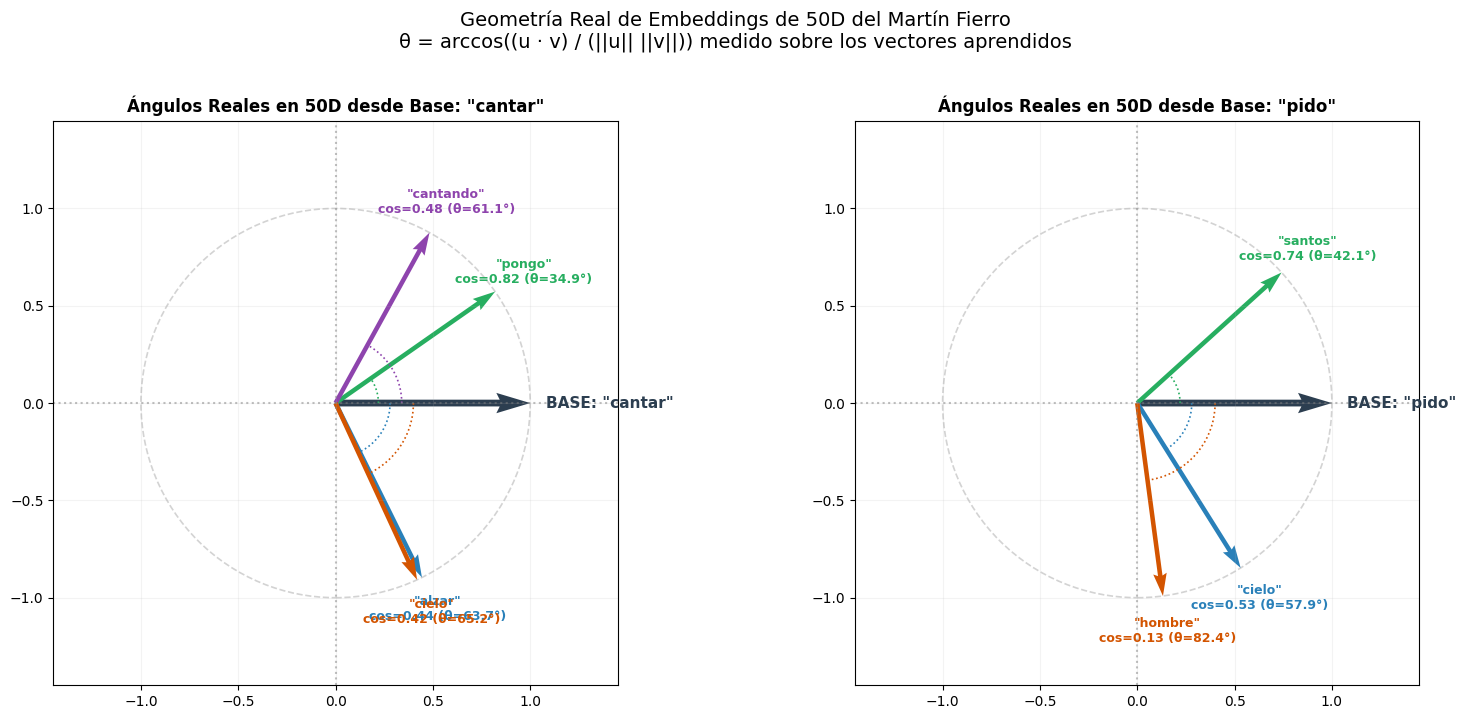

## 📜 Generación de Texto Guiada Semánticamente usando Word2Vec
Dado que Word2Vec no es un modelo de lenguaje probabilístico autoregresivo, podemos simular la generación de texto explotando su espacio semántico. La idea es que, a partir de una palabra inicial, la siguiente palabra sea una de sus vecinas más cercanas en el espacio de 50D, seleccionada mediante un muestreo probabilístico basado en sus similitudes de coseno.

In [ ]:
print("--- GENERACIÓN SEMÁNTICA CON WORD2VEC ---")
seeds = ['pido', 'cantar', 'gaucho', 'santos', 'cielo']

for sem in seeds:
    texto_gen = w2v.gen_text(sem, 15, 0.9, 10)
    print(f"\nSemilla: '{sem}'")
    print(f"-> Texto generado: '{texto_gen}'")

--- GENERACIÓN SEMÁNTICA CON WORD2VEC ---

Semilla: 'pido'
-> Texto generado: 'pido pensamiento cielo dormir pitar llevara pone hembraje mazamorra alboroto codo mazamorra ajuera moreno puso'

Semilla: 'cantar'
-> Texto generado: 'cantar pecho pastos facon ginebra porron trago hice corte tiento acabe alla pucha tiempo cerro'

Semilla: 'gaucho'
-> Texto generado: 'gaucho zorro quiere perseguido ande nido pecho ella quiere mula manejan vida despedicion riunir cerda'

Semilla: 'santos'
-> Texto generado: 'santos quema cielo dormir pitar llevara pone hembraje mazamorra alboroto codo mazamorra ajuera moreno puso'

Semilla: 'cielo'
-> Texto generado: 'cielo santos vengan dentro vengan todos aqui hacerme queria ese hoy ningun bala ternero toro'


### Material Complementario

- [WORD2VEC DESDE CERO: de Texto a Vectores](https://www.youtube.com/watch?v=T257Zw9BoT0)
- [Word Embedding and Word2Vec, Clearly Explained!!!](https://www.youtube.com/watch?v=viZrOnJclY0)
- [A Dummy’s Guide to Word2Vec](https://medium.com/@manansuri/a-dummys-guide-to-word2vec-456444f3c673)